In [ ]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.6 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [ ]:
from pathlib import Path
from google.colab import userdata
from roboflow import Roboflow

project_folder = Path("/content/ODOL")

raw_dataset_folder = project_folder / "dataset" / "raw"
results_folder = project_folder / "results"

raw_dataset_folder.mkdir(parents=True, exist_ok=True)
results_folder.mkdir(parents=True, exist_ok=True)

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

project = rf.workspace("sigara-hpnoo").project("truck-over-dimension-brupr")

dataset = project.version(2).download("yolov8",location="/content/ODOL/dataset/raw/truck-over-dimension")

source_dataset = Path(dataset.location)

source_dataset

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/ODOL/dataset/raw/truck-over-dimension in yolov8:: 100%|██████████| 5718/5718 [00:02<00:00, 2506.27it/s]


PosixPath('/content/ODOL/dataset/raw/truck-over-dimension')

In [ ]:
import yaml

data_yaml = source_dataset / "data.yaml"

data = yaml.safe_load(data_yaml.read_text())
class_names = data["names"]

class_names

['NOT ODOL', 'ODOL']

In [ ]:
image_label_pairs = []

for split_name in ["train","valid","test"]:
    image_folder = source_dataset / split_name / "images"
    label_folder = source_dataset / split_name / "labels"

    for image_file in sorted(image_folder.glob("*.jpg")):
        label_file = label_folder / f"{image_file.stem}.txt"
        image_label_pairs.append((split_name,image_file,label_file))

len(image_label_pairs)

2853

In [ ]:
image_groups = {}

for split_name,image_file,label_file in image_label_pairs:
    original_name = image_file.stem.split(".rf.")[0]

    if original_name not in image_groups:
        image_groups[original_name] = []

    image_groups[original_name].append((split_name,image_file,label_file))

len(image_groups)

1095

In [ ]:
groups_in_multiple_splits = 0

for group_items in image_groups.values():
    split_names = {item[0] for item in group_items}

    if len(split_names) > 1:
        groups_in_multiple_splits += 1

groups_in_multiple_splits

0

In [ ]:
from sklearn.model_selection import train_test_split

# 1. label each group by its boxes: 1 = contains ODOL, 0 = only NOT ODOL
group_names = sorted(image_groups.keys())
group_labels = []
for g in group_names:
    has_odol = False
    for split_name, image_file, label_file in image_groups[g]:
        for line in label_file.read_text().splitlines():
            if int(line.split()[0]) == 1:
                has_odol = True
                break
        if has_odol:
            break
    group_labels.append(1 if has_odol else 0)

# 2. re-split GROUPS 70/15/15, stratified
train_groups, temp_groups, _, temp_labels = train_test_split(
    group_names, group_labels, test_size=0.30, stratify=group_labels, random_state=42
)
valid_groups, test_groups = train_test_split(
    temp_groups, test_size=0.5, stratify=temp_labels, random_state=42
)

print(len(train_groups), len(valid_groups), len(test_groups))

group_to_new_split = {}
for g in train_groups: group_to_new_split[g] = "train"
for g in valid_groups: group_to_new_split[g] = "valid"
for g in test_groups: group_to_new_split[g] = "test"


766 164 165


In [ ]:
split_name,image_file,label_file = image_label_pairs[0]

label_file.read_text()

'1 0.770855090625 1 0.7769230765625 0.9827849000000001 0.784615384375 0.8156837609375 0.79076923125 0.43600284843750003 0.7769230765625 0.3827849 0.7184615390625 0.2997535609375 0.684615384375 0.28299857500000003 0.5538461531250001 0.27371794843749997 0.466153846875 0.276670940625 0.4523076921875 0.2884529921875 0.455384615625 0.6336125359375 0.48 0.7123888890625001 0.49230769218750003 0.890527065625 0.5323076921875 0.9326011390625 0.5422426734375 1 0.770855090625 1\n1 0.45846153906250003 0.041272079687500005 0.3476923078125 0.045528490625 0.33999999999999997 0.0551296296875 0.3369230765625 0.0849700859375 0.3369230765625 0.19997008593750001 0.36307692343750003 0.4638262109375 0.3769230765625 0.48454415937500006 0.3815384609375 0.514783475 0.45076923124999996 0.52087321875 0.4569230765625 0.5061923078125 0.455384615625 0.3146125359375 0.48923076875 0.277867521875 0.5523076921875 0.2711381765625 0.54923076875 0.1184786328125 0.5076923078125 0.05132478593749999 0.45846153906250003 0.0412

In [ ]:
import cv2
import shutil

crop_dataset = project_folder / "dataset" / "mobilenet"

shutil.rmtree(crop_dataset,ignore_errors=True)

for split_name,image_file,label_file in image_label_pairs:
    original_name = image_file.stem.split(".rf.")[0]
    split_name = group_to_new_split[original_name]
    image = cv2.imread(image_file)
    height,width = image.shape[:2]

    for crop_number,line in enumerate(label_file.read_text().splitlines()):
        parts = line.split()
        class_id = int(parts[0])

        if len(parts) == 5:
            center_x,center_y,box_width,box_height = [float(value) for value in parts[1:]]

            x1 = int((center_x - box_width / 2) * width)
            y1 = int((center_y - box_height / 2) * height)
            x2 = int((center_x + box_width / 2) * width)
            y2 = int((center_y + box_height / 2) * height)

        else:
            x_values = [float(parts[index]) for index in range(1,len(parts),2)]
            y_values = [float(parts[index]) for index in range(2,len(parts),2)]

            x1 = int(min(x_values) * width)
            y1 = int(min(y_values) * height)
            x2 = int(max(x_values) * width)
            y2 = int(max(y_values) * height)

        x1 = max(0,min(x1,width))
        y1 = max(0,min(y1,height))
        x2 = max(0,min(x2,width))
        y2 = max(0,min(y2,height))

        class_folder = crop_dataset / split_name / class_names[class_id].replace(" ","_")
        class_folder.mkdir(parents=True,exist_ok=True)

        crop = image[y1:y2,x1:x2]
        crop_path = class_folder / f"{image_file.stem}_{crop_number}.jpg"

        cv2.imwrite(crop_path,crop)

crop_dataset

PosixPath('/content/ODOL/dataset/mobilenet')

In [ ]:
for split_name in ["train","valid","test"]:
    print(split_name)

    for class_name in class_names:
        class_folder = crop_dataset / split_name / class_name.replace(" ","_")
        crop_count = len(list(class_folder.glob("*.jpg")))

        print(class_name,crop_count)

train
NOT ODOL 884
ODOL 710
valid
NOT ODOL 211
ODOL 160
test
NOT ODOL 184
ODOL 155


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_data = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=8,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    brightness_range=[0.85, 1.15],
    horizontal_flip=True
)

valid_data = ImageDataGenerator(preprocessing_function=preprocess_input)
test_data = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_data.flow_from_directory(
    crop_dataset / "train",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=True,
    seed=42
)

valid_generator = valid_data.flow_from_directory(
    crop_dataset / "valid",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

test_generator = test_data.flow_from_directory(
    crop_dataset / "test",
    target_size=(224,224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

train_generator.class_indices

Found 1594 images belonging to 2 classes.
Found 371 images belonging to 2 classes.
Found 339 images belonging to 2 classes.


{'NOT_ODOL': 0, 'ODOL': 1}

In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D,Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
output = Dense(1,activation="sigmoid")(x)

model = Model(inputs=base_model.input,outputs=output)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

final_model_path = (
    results_folder
    / "mobilenet_odol_classifier.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=15,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath=final_model_path,
        monitor="val_accuracy",
        save_best_only=True
    )
]

history = model.fit(
    train_generator,
    epochs=100,
    validation_data=valid_generator,
    callbacks=callbacks
)

# Phase 2: fine-tune top layers with tiny LR
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks2 = [
    EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True),
    ModelCheckpoint(filepath=final_model_path, monitor="val_accuracy", save_best_only=True)
]

history2 = model.fit(
    train_generator,
    epochs=30,
    validation_data=valid_generator,
    callbacks=callbacks2
)

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.6587 - loss: 0.6075 - val_accuracy: 0.6577 - val_loss: 0.5741
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 507ms/step - accuracy: 0.7992 - loss: 0.4630 - val_accuracy: 0.7574 - val_loss: 0.4861
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 512ms/step - accuracy: 0.8325 - loss: 0.4103 - val_accuracy: 0.7682 - val_loss: 0.4669
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 513ms/step - accuracy: 0.8463 - loss: 0.3752 - val_accuracy: 0.8194 - val_loss: 0.4178
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 510ms/step - accuracy: 0.8720 - loss: 0.3390 - val_accuracy: 0.8275 - val_loss: 0.4107
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 510ms/step - accuracy: 0.8827 - loss: 0.3189 - val_accuracy: 0.8437 - val_loss: 0.3921
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 517ms/step - accuracy: 0.8676 - loss: 0.3187 - val_accuracy: 0.8491 - val_loss: 0.3712
Epoch 8/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 493ms/step - accuracy: 0.9040 - loss: 0.2867 - val

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

test_generator.reset()

predictions = model.predict(test_generator)

y_true = test_generator.classes
y_pred = (predictions > 0.5).astype(int).ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
matrix = confusion_matrix(y_true, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 score:", round(f1, 4))
print("Confusion matrix:")
print(matrix)

11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 485ms/step
Accuracy: 0.9056
Precision: 0.8917
Recall: 0.9032
F1 score: 0.8974
Confusion matrix:
[[167  17]
 [ 15 140]]


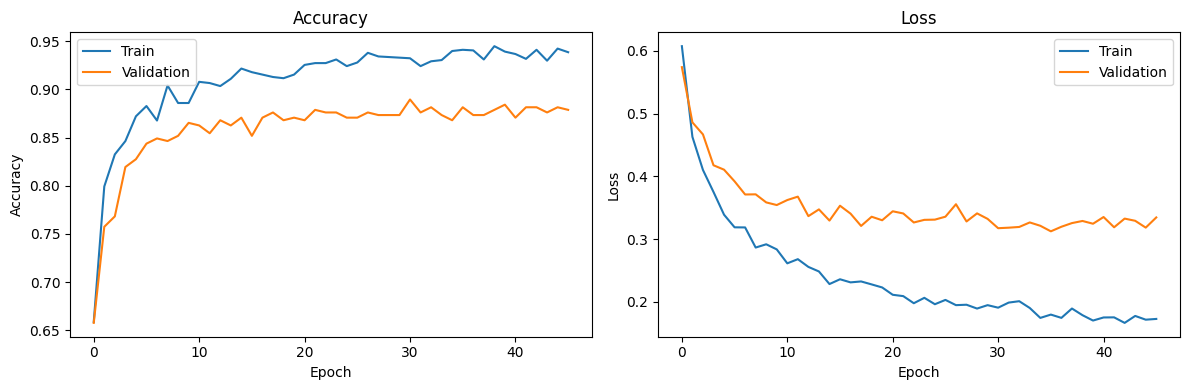

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig(
    "/content/ODOL/results/mobilenet_training_history.png"
)
plt.show()

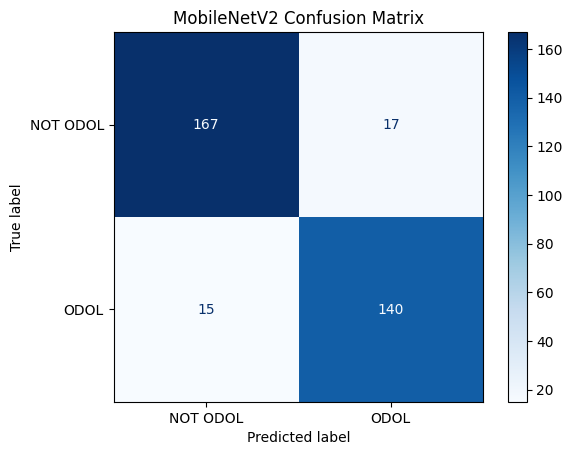

              precision    recall  f1-score   support

    NOT ODOL       0.92      0.91      0.91       184
        ODOL       0.89      0.90      0.90       155

    accuracy                           0.91       339
   macro avg       0.90      0.91      0.91       339
weighted avg       0.91      0.91      0.91       339



In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
)

display.plot(cmap="Blues", values_format="d")

plt.title("MobileNetV2 Confusion Matrix")
plt.savefig(
    "/content/ODOL/results/mobilenet_confusion_matrix.png"
)
plt.show()

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

In [ ]:
model.save(final_model_path)

final_model_path

PosixPath('/content/ODOL/results/mobilenet_odol_classifier.keras')

In [ ]:
from tensorflow.keras.models import load_model

classifier_model = load_model(final_model_path)

classifier_model

<Functional name=functional, built=True>

In [ ]:
from google.colab import files

files.download(str(final_model_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>